# Plot hexagons

In [1]:
!pwd



/net/home/swolf/Func_Neo_Phytes/notebooks


In [ ]:
# set working directory
import os
os.chdir("/net/home/swolf/Func_Neo_Phytes/")

: 

### Load summary stats at hexagon level

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import h3pandas

In [4]:
#data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_samples/550_res4_all_native.csv")
#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_s100_1000_summary_stats_inkl_pca.csv")
#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res4_res3_try6_mean.csv")
#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res4_res3_try6_s100_s1000_mean_2.csv")
#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_s100_s100_mean_1st_99th_percentile.csv")

# good # summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_mean_trim01.csv")
# finally good # summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_s100_5000_mean_trim01.csv")

# yes! # summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_glonaf_s1_5000_mean_trim01.csv")
#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_mean_trim01_cs.csv") #check for CS data

# summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_summary_stats.csv")

## MEDIAN ## 
#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_summary_stats_inkl_pca.csv")

## MEAN ##
#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_summary_stats_inkl_pca_mean.csv")

## MEAN CS ##
#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_summary_stats_inkl_pca_mean.csv")

## new without major error in filtering:##
#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_all_summary_stats_inkl_pca_mean.csv")

#### final ##### 
summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10.csv")
#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_angio.csv")

#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_h3/aggregated_longevity.csv")


#summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_n100.csv")

summary_data.head()

,h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC1_percent_change,...,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
0,832830fffffffff,-1.803834,-1.354830,0.960375,0.158118,-0.056053,-0.613122,0.287040,0.477826,-33.141024,...,-0.864,55.17,44.21,0.442,0.471,0.430,0.461,-6.16,-6.72,h3_res3
1,832834fffffffff,-1.781438,-1.299022,0.500644,-0.298288,-0.166184,-0.699030,0.483950,0.659214,-37.136897,...,-0.970,46.71,23.30,0.453,0.478,0.449,0.471,-5.23,-4.67,h3_res3
2,832831fffffffff,-1.976354,-1.591604,0.911294,0.362401,-0.617326,-1.125287,-0.064579,0.036306,-24.173716,...,-1.237,39.56,32.01,0.442,0.460,0.437,0.458,-3.91,-4.59,h3_res3
3,832655fffffffff,-0.260563,0.074816,2.567610,2.401411,-0.617178,-1.114999,0.404722,0.255304,-448.273661,...,-0.276,86.05,9.42,0.438,0.448,0.435,0.438,-2.23,-0.68,h3_res3
4,832a16fffffffff,-0.842443,-0.258770,2.920063,2.595814,-0.886080,-2.106082,0.459177,0.578602,-225.556026,...,-0.860,56.99,61.86,0.423,0.442,0.406,0.426,-4.30,-4.69,h3_res3


In [5]:
# read ~/Func_Neo_Phytes/Data/h3_population_density.csv

pop_density= pd.read_csv("~/Func_Neo_Phytes/Data/h3_population_density.csv")
pop_density.head()



,h3,density
0,830001fffffffff,0.081605
1,830005fffffffff,0.122407
2,83000cfffffffff,0.061204
3,830011fffffffff,0.036079
4,830018fffffffff,0.036079


In [6]:
# merge summary_data and conifers on h3_res3 
summary_data = pd.merge(summary_data, pop_density, left_on='h3_res3', right_on='h3', how='left')
summary_data.head()

,h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC1_percent_change,...,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution,h3,density
0,832830fffffffff,-1.803834,-1.354830,0.960375,0.158118,-0.056053,-0.613122,0.287040,0.477826,-33.141024,...,44.21,0.442,0.471,0.430,0.461,-6.16,-6.72,h3_res3,832830fffffffff,126.986240
1,832834fffffffff,-1.781438,-1.299022,0.500644,-0.298288,-0.166184,-0.699030,0.483950,0.659214,-37.136897,...,23.30,0.453,0.478,0.449,0.471,-5.23,-4.67,h3_res3,832834fffffffff,1040.862300
2,832831fffffffff,-1.976354,-1.591604,0.911294,0.362401,-0.617326,-1.125287,-0.064579,0.036306,-24.173716,...,32.01,0.442,0.460,0.437,0.458,-3.91,-4.59,h3_res3,832831fffffffff,9.656569
3,832655fffffffff,-0.260563,0.074816,2.567610,2.401411,-0.617178,-1.114999,0.404722,0.255304,-448.273661,...,9.42,0.438,0.448,0.435,0.438,-2.23,-0.68,h3_res3,832655fffffffff,30.953556
4,832a16fffffffff,-0.842443,-0.258770,2.920063,2.595814,-0.886080,-2.106082,0.459177,0.578602,-225.556026,...,61.86,0.423,0.442,0.406,0.426,-4.30,-4.69,h3_res3,832a16fffffffff,131.862780


In [5]:
longevity= pd.read_csv("/net/scratch/swolf/GBIF/gbif_h3/aggregated_longevity.csv")
longevity.head()

,h3_res3,annual_count,perennial_count,total_count,annual_percentage,perennial_percentage
0,833db6fffffffff,46,105,151,30.463576,69.536424
1,8344dcfffffffff,656,4826,5482,11.966436,88.033564
2,8344d8fffffffff,2378,15292,17670,13.457838,86.542162
3,83961afffffffff,2,15,17,11.764706,88.235294
4,8344cdfffffffff,4109,32985,37094,11.077263,88.922737


In [ ]:
# filter longevity for h3_res3 and annual_percentage and perennial_percentage
longevity = longevity[["h3_res3",
                       "annual_percentage",
                       "perennial_percentage"]]

In [ ]:
# merge summary_data and conifers on h3_res3 
summary_data = pd.merge(summary_data, longevity, left_on='h3_res3', right_on='h3_res3', how='left')
summary_data.head()

In [8]:
conifers = pd.read_csv("/net/scratch/swolf/GBIF/gbif_h3/aggregated_res3_conifers.csv")


In [9]:
# rename "N" "conifer_count"
conifers.rename(columns={"N": "conifer_count"}, inplace=True)

In [10]:
conifers.head()

,h3_res3,conifer_count
0,83194afffffffff,2120
1,831951fffffffff,1049
2,83194efffffffff,520
3,83195efffffffff,460
4,831973fffffffff,584


In [11]:
# merge summary_data and conifers on h3_res3 
summary_data = pd.merge(summary_data, conifers, left_on='h3_res3', right_on='h3_res3', how='left')
summary_data.head()

,h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC1_percent_change,...,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution,annual_percentage,perennial_percentage,conifer_count
0,832830fffffffff,-1.803834,-1.354830,0.960375,0.158118,-0.056053,-0.613122,0.287040,0.477826,-33.141024,...,0.442,0.471,0.430,0.461,-6.16,-6.72,h3_res3,27.381305,72.618695,8795.0
1,832834fffffffff,-1.781438,-1.299022,0.500644,-0.298288,-0.166184,-0.699030,0.483950,0.659214,-37.136897,...,0.453,0.478,0.449,0.471,-5.23,-4.67,h3_res3,26.763215,73.236785,10079.0
2,832831fffffffff,-1.976354,-1.591604,0.911294,0.362401,-0.617326,-1.125287,-0.064579,0.036306,-24.173716,...,0.442,0.460,0.437,0.458,-3.91,-4.59,h3_res3,19.758532,80.241468,2200.0
3,832655fffffffff,-0.260563,0.074816,2.567610,2.401411,-0.617178,-1.114999,0.404722,0.255304,-448.273661,...,0.438,0.448,0.435,0.438,-2.23,-0.68,h3_res3,14.723188,85.276812,164.0
4,832a16fffffffff,-0.842443,-0.258770,2.920063,2.595814,-0.886080,-2.106082,0.459177,0.578602,-225.556026,...,0.423,0.442,0.406,0.426,-4.30,-4.69,h3_res3,7.050316,92.949684,2310.0


In [12]:
perc_woody = pd.read_csv("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_all_CS_log10_woody.csv")
perc_woody.head()

,h3_cell,V1,V2,V3,V4,V5,V6,V7,V8,X.X3117..mean_all,...,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
0,832830fffffffff,534527,378645,2065,1241,173836,343606,32.45,64.14,18.214,...,-0.864,55.17,44.21,0.442,0.471,0.430,0.461,-6.16,-6.72,h3_res3
1,832834fffffffff,449715,334995,1791,1055,163478,274171,36.21,60.72,17.946,...,-0.970,46.71,23.30,0.453,0.478,0.449,0.471,-5.23,-4.67,h3_res3
2,832831fffffffff,64487,51697,1264,773,20596,41557,31.90,64.37,18.615,...,-1.237,39.56,32.01,0.442,0.460,0.437,0.458,-3.91,-4.59,h3_res3
3,832655fffffffff,18573,14586,970,732,5902,12240,31.58,65.50,22.796,...,-0.276,86.05,9.42,0.438,0.448,0.435,0.438,-2.23,-0.68,h3_res3
4,832a16fffffffff,62447,38917,1411,851,25333,34918,40.37,55.65,24.879,...,-0.860,56.99,61.86,0.423,0.442,0.406,0.426,-4.30,-4.69,h3_res3


In [13]:
# filter perc_woody fo columns h3_res3 and V7, V8
perc_woody = perc_woody[["h3_cell", "V7", "V8"]]

#rename V7 to perc_woody and V8 to perc_nonwoody
perc_woody.rename(columns={"V7": "perc_woody", "V8": "perc_nonwoody"}, inplace=True)
perc_woody.head()

,h3_cell,perc_woody,perc_nonwoody
0,832830fffffffff,32.45,64.14
1,832834fffffffff,36.21,60.72
2,832831fffffffff,31.90,64.37
3,832655fffffffff,31.58,65.50
4,832a16fffffffff,40.37,55.65


In [26]:
# merge summary_data and conifers on h3_res3 
summary_data = pd.merge(summary_data, perc_woody, left_on='h3_res3', right_on='h3_cell', how='left')
summary_data.head()

NameError: name 'perc_woody' is not defined

In [15]:
# print columns
summary_data.columns


Index(['h3_res3', 'PC1_all', 'PC1_native', 'PC2_all', 'PC2_native', 'PC3_all',
       'PC3_native', 'PC4_all', 'PC4_native', 'PC1_percent_change',
       ...
       'X.X4..median_native', 'X.X4..percent_change_mean',
       'X.X4..percent_change_median', 'resolution', 'annual_percentage',
       'perennial_percentage', 'conifer_count', 'h3_cell', 'perc_woody',
       'perc_nonwoody'],
      dtype='object', length=244)

In [30]:
summary_data['woodyXperennial'] = (summary_data['perc_woody'] * summary_data['perennial_percentage'])

In [16]:
## Calculate percentage conifers
summary_data['conifer_percentage'] = (summary_data['conifer_count'] / summary_data['count_all']) * 100

In [30]:
summary_data.head()

,h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC1_percent_change,...,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution,perc_naturalized,perc_naturalized_sp,h3,density
0,832830fffffffff,-1.803834,-1.354830,0.960375,0.158118,0.056053,0.613122,0.287040,0.477826,-33.141024,...,0.471,0.430,0.461,-6.16,-6.72,h3_res3,29.162605,39.903148,832830fffffffff,126.986240
1,832834fffffffff,-1.781438,-1.299022,0.500644,-0.298288,0.166184,0.699030,0.483950,0.659214,-37.136897,...,0.478,0.449,0.471,-5.23,-4.67,h3_res3,25.509489,41.094361,832834fffffffff,1040.862300
2,832831fffffffff,-1.976354,-1.591604,0.911294,0.362401,0.617326,1.125287,-0.064579,0.036306,-24.173716,...,0.460,0.437,0.458,-3.91,-4.59,h3_res3,19.833455,38.844937,832831fffffffff,9.656569
3,832655fffffffff,-0.260563,0.074816,2.567610,2.401411,0.617178,1.114999,0.404722,0.255304,-448.273661,...,0.448,0.435,0.438,-2.23,-0.68,h3_res3,21.466645,24.536082,832655fffffffff,30.953556
4,832a16fffffffff,-0.842443,-0.258770,2.920063,2.595814,0.886080,2.106082,0.459177,0.578602,-225.556026,...,0.442,0.406,0.426,-4.30,-4.69,h3_res3,37.679953,39.688164,832a16fffffffff,131.862780


### Calculate percentage naturalized


In [22]:
# flip sign of Pc3 and PC4 if needed
summary_data['PC3_all'] = -summary_data['PC3_all']
summary_data['PC3_native'] = -summary_data['PC3_native']

#summary_data['PC2_all'] = -summary_data['PC2_all']
#summary_data['PC2_native'] = -summary_data['PC2_native']

In [7]:
# Add a new column 'ratio' as the fraction of 'column1' and 'column2'

summary_data['perc_naturalized'] = (summary_data['count_all'] - summary_data['count_native']) / summary_data['count_all']*100


In [8]:
summary_data['perc_naturalized_sp'] = (summary_data['count_sp_all'] - summary_data['count_sp_native']) / summary_data['count_sp_all']*100


In [9]:
summary_data.head()

,h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC1_percent_change,...,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution,h3,density,perc_naturalized,perc_naturalized_sp
0,832830fffffffff,-1.803834,-1.354830,0.960375,0.158118,-0.056053,-0.613122,0.287040,0.477826,-33.141024,...,0.471,0.430,0.461,-6.16,-6.72,h3_res3,832830fffffffff,126.986240,29.162605,39.903148
1,832834fffffffff,-1.781438,-1.299022,0.500644,-0.298288,-0.166184,-0.699030,0.483950,0.659214,-37.136897,...,0.478,0.449,0.471,-5.23,-4.67,h3_res3,832834fffffffff,1040.862300,25.509489,41.094361
2,832831fffffffff,-1.976354,-1.591604,0.911294,0.362401,-0.617326,-1.125287,-0.064579,0.036306,-24.173716,...,0.460,0.437,0.458,-3.91,-4.59,h3_res3,832831fffffffff,9.656569,19.833455,38.844937
3,832655fffffffff,-0.260563,0.074816,2.567610,2.401411,-0.617178,-1.114999,0.404722,0.255304,-448.273661,...,0.448,0.435,0.438,-2.23,-0.68,h3_res3,832655fffffffff,30.953556,21.466645,24.536082
4,832a16fffffffff,-0.842443,-0.258770,2.920063,2.595814,-0.886080,-2.106082,0.459177,0.578602,-225.556026,...,0.442,0.406,0.426,-4.30,-4.69,h3_res3,832a16fffffffff,131.862780,37.679953,39.688164


## Correlation with pop density

In [38]:
# remove from summary_data all rows where count_all is less than 10
summary_data = summary_data[summary_data['count_all'] >= 10]

In [63]:
corr = summary_data['log_count_all'].corr(summary_data['perc_naturalized'])

print(f"Correlation between pop_density and %introduced obs: {corr}")  

Correlation between pop_density and %introduced obs: 0.016767198996288563


In [39]:
import numpy as np
# calculate and plot correlation between human population density and percent introduced species
# Replace zero or negative values in 'density' with NaN to avoid log10 issues
summary_data['density'] = summary_data['density'].replace(0, np.nan)
summary_data['log_density'] = np.log10(summary_data['density'])

# Calculate correlation
corr = summary_data['log_density'].corr(summary_data['perc_naturalized'])

print(f"Correlation between pop_density and %introduced obs: {corr}")  

Correlation between pop_density and %introduced obs: 0.5173370028742417


In [55]:
# test significance of correlation
from scipy.stats import pearsonr
# Drop rows with NaN values in the relevant columns
corr_data = summary_data.dropna(subset=['log_density', 'perc_naturalized'])
# Calculate Pearson correlation and p-value
corr_coeff, p_value = pearsonr(corr_data['log_density'], corr_data['perc_naturalized'])
print(f"Pearson correlation coefficient: {corr_coeff}, p-value: {p_value:.2e}")
# Calculate correlation with species count instead of percentage
corr_sp = summary_data['log_density'].corr(summary_data['perc_naturalized_sp'])
print(f"Correlation between pop_density and %introduced species count: {corr_sp}")
corr_sp2 = summary_data['density'].corr(summary_data['perc_naturalized_sp'])
print(f"Correlation between pop_density (not log) and %introduced species count: {corr_sp2}")


Pearson correlation coefficient: 0.5173370028742414, p-value: 0.00e+00
Correlation between pop_density and %introduced species count: 0.5041646203874888
Correlation between pop_density (not log) and %introduced species count: 0.2704202892118669


In [40]:
# Calculate correlation
corr_sp = summary_data['log_density'].corr(summary_data['perc_naturalized_sp'])

print(f"Correlation between pop_density and %introduced species count: {corr_sp}") 

Correlation between pop_density and %introduced species count: 0.5041646203874888


/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/seaborn/axisgrid.py:88: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


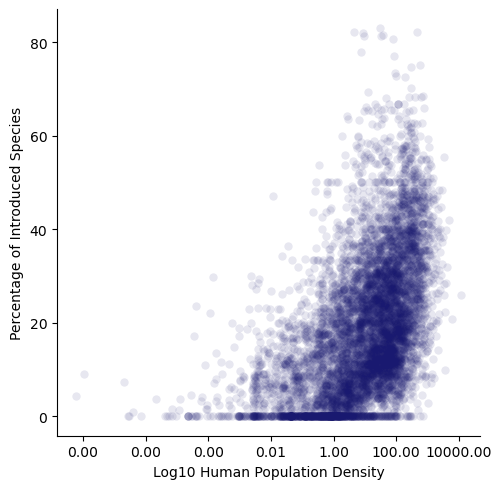

In [58]:
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.pyplot as plt

# Define the variables for the plot
x = 'log_density'
y = 'perc_naturalized_sp'
col = None  # Set to a column name if you want to create facets
col_wrap = None  # Set to an integer if you want to wrap facets

# Create the scatter plot using relplot
g = sns.relplot(
    data=summary_data,
    x=x, y=y,
    col=col, 
    kind="scatter", 
    col_wrap=col_wrap, 
    linewidth=0,
    alpha=0.1,
    color="midnightblue",
    palette='crest',
    facet_kws={'sharey': False, 'sharex': False}
)

# Add titles and labels
g.set_axis_labels("Log10 Human Population Density", "Percentage of Introduced Species")
#g.fig.suptitle("Correlation between Population Density and % Naturalized Species", y=1.02)

# Back-transform x-axis ticks with decimals
def back_transform(value, _):
    return f"{10**value:.2f}"

for ax in g.axes.flat:
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(back_transform))

plt.show()

# save figure png
g.savefig("../Results/Figures/Correlation_PopDensity_PercentNaturalizedSpecies.png", dpi=300, bbox_inches='tight')

In [23]:
# Calculate correlation
corr_sp2 = summary_data['density'].corr(summary_data['perc_naturalized_sp'])

print(f"Correlation between pop_density (not log) and %introduced species count: {corr_sp2}") 

Correlation between pop_density (not log) and %introduced species count: 0.24955365504176102


## Map hexagons

In [14]:
# add column with count_all and count_native in ln scale
import numpy as np

summary_data['log_count_all'] = np.log10(summary_data['count_all'])
summary_data['log_count_native'] = np.log10(summary_data['count_native'])


summary_data['log_count_all_sp'] = np.log10(summary_data['count_sp_all'])
summary_data['log_count_native_sp'] = np.log10(summary_data['count_sp_native'])

In [15]:

summary_data['count_non_native'] = summary_data['count_sp_all'] - summary_data['count_sp_native']
summary_data['log_count_non_native'] = np.log10(summary_data['count_non_native'])

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [24]:
# calculate differences between native and all for PC1 and PC2
summary_data['PC1_diff'] = summary_data['PC1_all'] - summary_data['PC1_native']
summary_data['PC2_diff'] = summary_data['PC2_all'] - summary_data['PC2_native']
summary_data['PC3_diff'] = summary_data['PC3_all'] - summary_data['PC3_native']
summary_data['PC4_diff'] = summary_data['PC4_all'] - summary_data['PC4_native']


### Create GeoDataFrame and Clean Geometries

This code block converts H3 hexagon indices to polygons, wraps longitudes to the range [-180, 180], and creates a GeoDataFrame. Invalid geometries and polygons spanning more than 180° longitude are removed to ensure clean and accurate spatial data for further analysis.




In [16]:
final_df = summary_data.copy()

In [17]:
import geopandas as gpd
import h3
from shapely.geometry import Polygon
from shapely.ops import transform
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Function to convert H3 cell to polygon
def h3_to_polygon(h3_index):
    boundary = h3.h3_to_geo_boundary(h3_index, geo_json=True)
    return Polygon(boundary)

# Function to wrap longitudes to [-180, 180]
def wrap_geometry(geom):
    def wrap_coords(x, y):
        x_wrapped = ((x + 180) % 360) - 180
        return x_wrapped, y
    return transform(lambda x, y: wrap_coords(x, y), geom)

# Build geometry column
final_df["geometry"] = final_df["h3_res3"].apply(lambda x: wrap_geometry(h3_to_polygon(x)))

# Create GeoDataFrame
gdf = gpd.GeoDataFrame(final_df, geometry="geometry", crs="EPSG:4326")

# Fix column names
gdf.columns = gdf.columns.str.replace('.', '_')

# 💥 Remove invalid geometries and those spanning too much longitude
gdf = gdf[gdf.geometry.is_valid]  # remove invalid
gdf = gdf[gdf.bounds.maxx - gdf.bounds.minx < 180]  # remove polygons >180° wide


/tmp/ipykernel_1397545/3219989185.py:28: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  gdf.columns = gdf.columns.str.replace('.', '_')


### Plot world map 

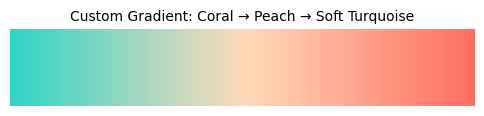

: 

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Define your custom colors
colors = [ "#2ed5c9", "#FFDAB9", "#FF6F61"]

# Create the colormap
native_non_cmap = mcolors.LinearSegmentedColormap.from_list("custom_gradient", colors)

# OPTIONAL: Visualize it with a gradient bar
gradient = np.linspace(0, 1, 256).reshape(1, -1)

plt.figure(figsize=(6, 1))

plt.imshow(gradient, aspect='auto', cmap=native_non_cmap)
plt.axis("off")
plt.title("Custom Gradient: Coral → Peach → Soft Turquoise", fontsize=10)
plt.show()


In [18]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Define your colors
low_color = "#2F86AC"      # like native_color
mid_color = "white"
high_color = "#b02f2c"     # like all_color

# Create a custom diverging colormap
div_cmap = mcolors.LinearSegmentedColormap.from_list(
    "custom_diverging",
    [low_color, mid_color, high_color]
)


In [32]:
# print gdf.columns with "_sp" 
for col in gdf.columns:
    if "mean_all" in col:
        print(col)

X_X3117__mean_all
X_X14__mean_all
X_X50__mean_all
X_X146__mean_all
X_X3120__mean_all
X_X224__mean_all
X_X297__mean_all
X_X21__mean_all
X_X13__mean_all
X_X15__mean_all
X_X3114__mean_all
X_X3113__mean_all
X_X3112__mean_all
X_X47__mean_all
X_X169__mean_all
X_X3106__mean_all
X_X144__mean_all
X_X27__mean_all
X_X26__mean_all
X_X55__mean_all
X_X46__mean_all
X_X281__mean_all
X_X282__mean_all
X_X289__mean_all
X_X163__mean_all
X_X145__mean_all
X_X3107__mean_all
X_X223__mean_all
X_X237__mean_all
X_X614__mean_all
X_X351__mean_all
X_X6__mean_all
X_X95__mean_all
X_X138__mean_all
X_X1080__mean_all
X_X78__mean_all
X_X4__mean_all


/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


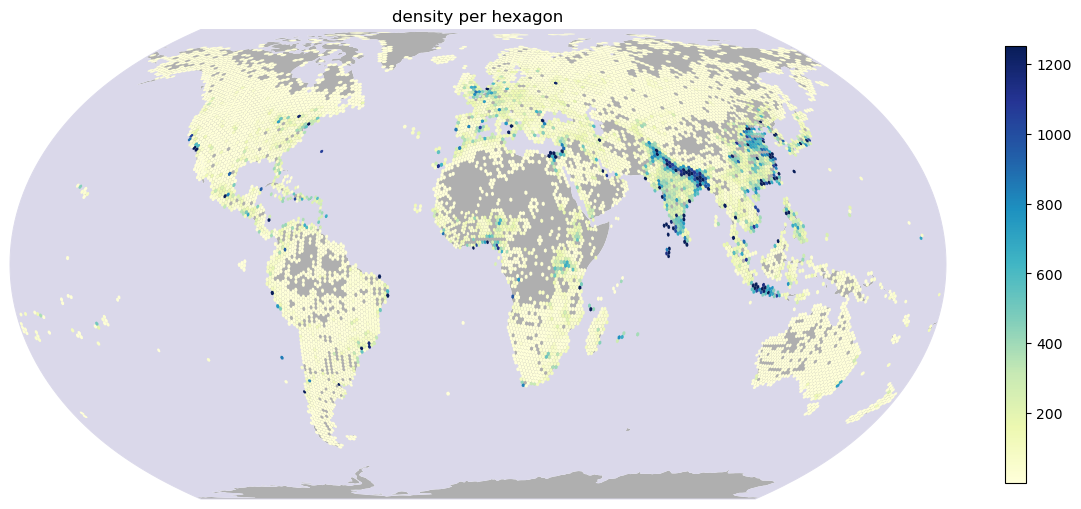

In [21]:
import os
import numpy as np
from matplotlib import colormaps


#pattern = "perc_naturalized"
#pattern = "log_"
#pattern = "X"
#pattern = "PC1_diff"
#pattern = "PC1_all"
#pattern = "PC2_percent_change"
#pattern = "PC"
#pattern = "count"
#pattern= "conifer_percentage"
#pattern= "perc_nonwoody"
# pattern = ".mean_all"
pattern= "density"



# Ensure the results directory exists
os.makedirs("Results/Figures", exist_ok=True)

# Loop over all columns that start with "X"
for column in [col for col in gdf.columns if col.startswith(pattern)]: 
#for column in [col for col in gdf.columns if "percent_change" in col]:
#for column in [col for col in gdf.columns if col.endswith("percent_change_median")]:
#for column in [col for col in gdf.columns if col.endswith("p_value")]:
#for column in [col for col in gdf.columns if col.endswith("rank_biserial_r")]:
#for column in [col for col in gdf.columns if col.endswith("mean_all")]:

    if "percent_change" in column:
        vmin, vmax = -80, 80
        cmap = div_cmap
    elif "rank_biserial_r" in column:
        vmin, vmax = -0.7, 0.7
        cmap = div_cmap
    elif "perc_naturalized" in column:
        cmap = "YlGnBu"
        vmin, vmax = 0, 100
    elif "conifer_percentage" in column:
        cmap = "YlGnBu"
        vmin, vmax = 0, 20
    elif "annual_percentage" in column:
        cmap = "YlGnBu_r"  # Inverted colormap
        vmin, vmax = 0, 40
    elif "PC1_diff" in column:
        vmin = np.nanpercentile(gdf[column], 5)
        vmax = np.nanpercentile(gdf[column], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    elif "PC2_diff" in column:
        vmin = np.nanpercentile(gdf["PC1_diff"], 5)
        vmax = np.nanpercentile(gdf["PC1_diff"], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    elif "PC3_diff" in column:
        vmin = np.nanpercentile(gdf["PC1_diff"], 5)
        vmax = np.nanpercentile(gdf["PC1_diff"], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    elif "PC4_diff" in column:
        vmin = np.nanpercentile(gdf["PC1_diff"], 5)
        vmax = np.nanpercentile(gdf["PC1_diff"], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    else:
        vmin = np.nanpercentile(gdf[column], 1)
        vmax = np.nanpercentile(gdf[column], 99)
        cmap = "YlGnBu"
        
    # Create plot with Robinson projection
    fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.EqualEarth()})
    #fig, ax = plt.subplots(figsize=(32, 18), subplot_kw={'projection': ccrs.EqualEarth()})
    
    ax.set_global()
    #ax.add_feature(cfeature.LAND, facecolor='#2F86AC', edgecolor='none')
    #ax.add_feature(cfeature.LAND, facecolor='lightgrey', edgecolor='none')
    ax.add_feature(cfeature.LAND, facecolor="#afafafff", edgecolor='none')
    ax.add_feature(cfeature.OCEAN, facecolor="#dad8eaff", edgecolor='none')
    #ax.add_feature(cfeature.LAND, facecolor='#A7AE9C', edgecolor='none')
    
    ax._autoscaleXon = True
    ax._autoscaleYon = True


    # Plot hexagons
    gdf.plot(
        column=column,
        cmap=cmap,
        vmin = vmin,
        vmax = vmax,
        legend=True,
        ax=ax,
        transform=ccrs.PlateCarree(),
        #edgecolor="black",
        linewidth=0.001,
        legend_kwds={"shrink": 0.45}
    )

    ax.set_title(f"{column} per hexagon", fontsize=12)
    #ax.set_title(f"Community science observations: {column} per hexagon", fontsize=14)
    #ax.set_title(f"GBIF sample (min. 1, max. 5000): Percent naturalized per hexagon", fontsize=14)
    
    #add coastlines
    #ax.coastlines(resolution='110m', color='#2F86AC', linewidth=0.7)
    #ax.coastlines(resolution='110m', color='pink', linewidth=0.9)
    #ax.coastlines(resolution='110m', color='pink', linewidth=2)
    

    #ax.coastlines(resolution='110m', color='#A7AE9C', linewidth=0.7)
    
    for spine in ax.spines.values():
        spine.set_edgecolor("#dad8eaff")       # Color of the frame
        spine.set_linewidth(0.7)           # Thickness of the frame
        #spine.set_linewidth(2)

    plt.tight_layout()
    
    # Save the plot
    output_path = f"Results/Figures/{column}_meanbased_trim01_GBIF_wcvp_CS_log10.png"
    #output_path = f"Results/Figures/{column}_meanbased_trim01_GBIF_wcvp_CS_n100.png"
    #output_path = f"Results/Figures/{column}_meanbased_trim01_GBIF_wcvp.png"
    #plt.savefig(output_path, format="pdf")
    plt.savefig(output_path, dpi=500, bbox_inches='tight')
    
    # Show the plot
    plt.show()

    

In [33]:
# calculate average perc_naturalized across all hexagons
# Trim outliers by excluding values outside the 1st and 99th percentiles
trimmed_data = gdf.loc[gdf['count_all'] > 100, 'perc_naturalized'].clip(
    lower=gdf['perc_naturalized'].quantile(0.01), 
    upper=gdf['perc_naturalized'].quantile(0.99)
)

# Calculate the average of the trimmed data
average_perc_naturalized = gdf.loc[gdf['count_all'] > 10000, 'perc_naturalized'].mean()
print(average_perc_naturalized)

average_perc_naturalized = gdf['perc_naturalized'].mean()
print(average_perc_naturalized)

18.981518920636244
16.124390387987425


In [20]:
# calculate average perc_naturalized across all hexagons
average_perc_naturalized = gdf['perc_naturalized_sp'].mean()
average_perc_naturalized

17.21818721017721

In [21]:
# for n100
# calculate average perc_naturalized across all hexagons
average_perc_naturalized = gdf['perc_naturalized_sp'].mean()
average_perc_naturalized

17.21818721017721

In [22]:
# Filter rows where count_all > 100
filtered_data = gdf[gdf['count_all'] > 100]

# Calculate correlation between log10(count_all) and perc_naturalized
correlation = np.log10(filtered_data['count_all']).corr(filtered_data['perc_naturalized'])
print(correlation)

-0.01532290066205216


In [23]:
# Filter rows where count_all > 100
filtered_data = gdf[gdf['count_all'] > 100]

# Calculate correlation between log10(count_all) and perc_naturalized
correlation = np.log10(filtered_data['count_all']).corr(filtered_data['perc_naturalized'])
print(correlation)

-0.01532290066205216


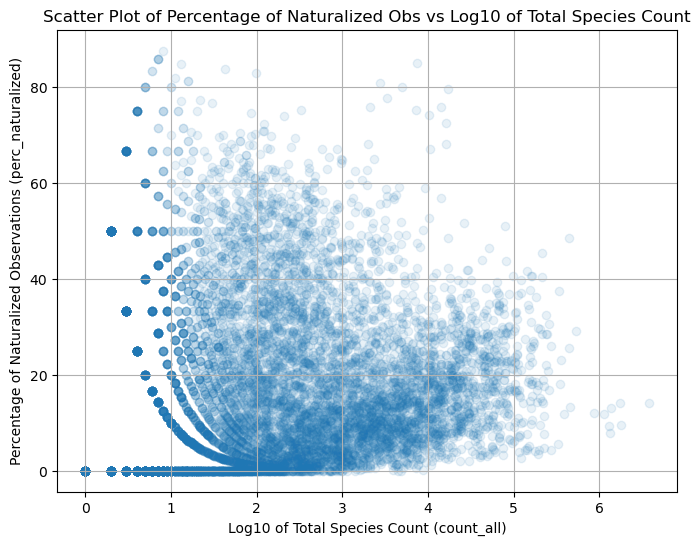

In [ ]:
# plot gdf['perc_naturalized'] ~ log10(gdf['count_all'])
plt.figure(figsize=(8,6))
plt.scatter(np.log10(gdf['count_all']), gdf['perc_naturalized'], alpha=0.1)
plt.xlabel('Log10 of Total Species Count (count_all)')
plt.ylabel('Percentage of Naturalized Observations (perc_naturalized)')
plt.title('Scatter Plot of Percentage of Naturalized Obs vs Log10 of Total Species Count')
plt.grid(True)

# Save the plot to a PDF file
plt.savefig("Results/Figures/scatter_plot_perc_naturalized_vs_obs_count.pdf", format="pdf", bbox_inches="tight")

plt.show()

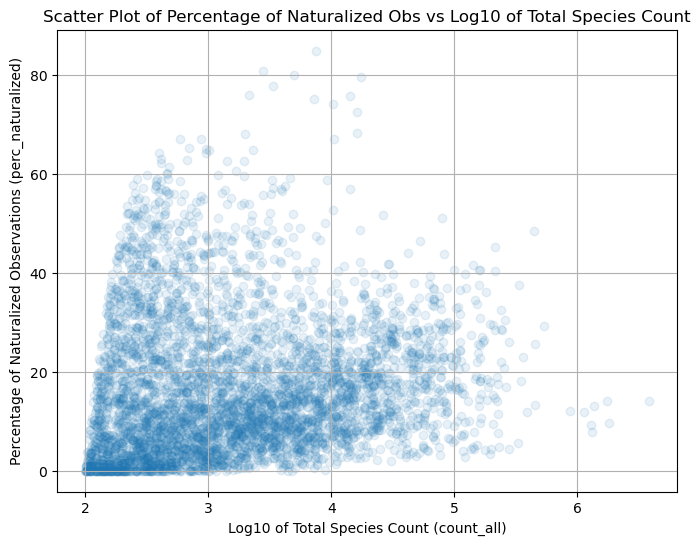

In [ ]:
# plot gdf['perc_naturalized'] ~ log10(gdf['count_all'])
plt.figure(figsize=(8,6))
plt.scatter(np.log10(gdf['count_all']), gdf['perc_naturalized'], alpha=0.1)
plt.xlabel('Log10 of Total Species Count (count_all)')
plt.ylabel('Percentage of Naturalized Observations (perc_naturalized)')
plt.title('Scatter Plot of Percentage of Naturalized Obs vs Log10 of Total Species Count')
plt.grid(True)

# Save the plot to a PDF file
plt.savefig("Results/Figures/scatter_plot_perc_naturalized_vs_obs_count.pdf", format="pdf", bbox_inches="tight")

plt.show()

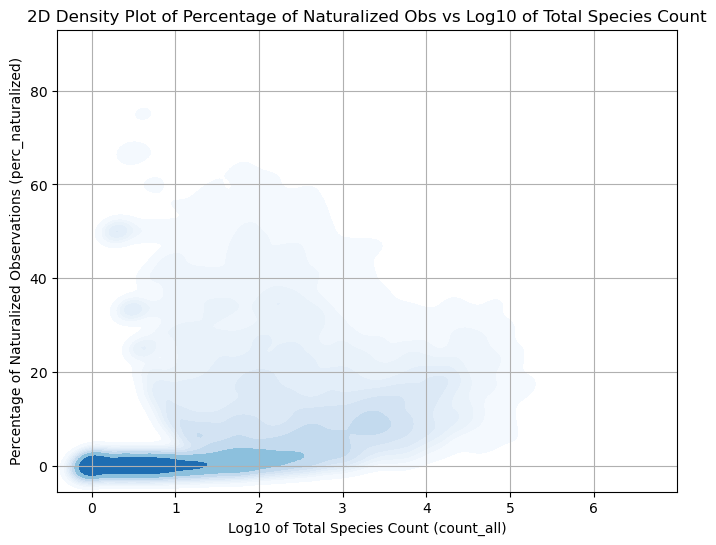

In [ ]:
import seaborn as sns

# Create a 2D density plot
plt.figure(figsize=(8, 6))
sns.kdeplot(
    x=np.log10(gdf['count_all']),
    y=gdf['perc_naturalized'],
    cmap="Blues",
    fill=True,
    bw_adjust=0.5
)
plt.xlabel('Log10 of Total Species Count (count_all)')
plt.ylabel('Percentage of Naturalized Observations (perc_naturalized)')
plt.title('2D Density Plot of Percentage of Naturalized Obs vs Log10 of Total Species Count')
plt.grid(True)

# Save the plot to a PDF file
plt.savefig("Results/Figures/density_plot_perc_naturalized_vs_obs_count.pdf", format="pdf", bbox_inches="tight")

plt.show()

## correlation PC3 and conifers

In [33]:
# calculate and plot correlation between PC3_all and percentage_conifer
correlation_pc3_conifers = gdf['PC3_all'].corr(gdf['conifer_percentage'])
print(f"Correlation between PC3_all and percentage of conifers: {correlation_pc3_conifers}")    


Correlation between PC3_all and percentage of conifers: 0.3954048076174503


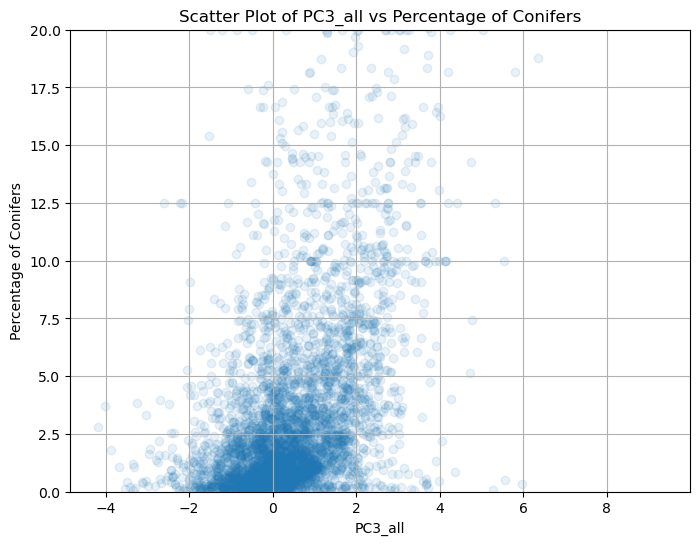

In [ ]:
# plot PC3_all vs percentage_conifer
plt.figure(figsize=(8, 6))
plt.scatter(gdf['PC3_all'], gdf['conifer_percentage'], alpha=0.1)
plt.xlabel('PC3_all')
plt.ylabel('Percentage of Conifers')
plt.title('Scatter Plot of PC3_all vs Percentage of Conifers')
plt.grid(True)

In [24]:
# calculate and plot correlation between PC3_all and percentagepercentage of annual species

correlation_pc3_annual_percentage = gdf['PC3_all'].corr(gdf['annual_percentage'])
print(f"Correlation between PC3_all and percentage of annuals: {correlation_pc3_annual_percentage}")    


Correlation between PC3_all and percentage of annuals: -0.34483735266432425


In [34]:
# calculate and plot correlation between PC3_all and percentagepercentage of annual species

correlation_pc3_annual_percentage = gdf['PC3_all'].corr(gdf['perennial_percentage'])
print(f"Correlation between PC3_all and percentage of perennials: {correlation_pc3_annual_percentage}")    


Correlation between PC3_all and percentage of perennials: 0.34483735266432425


In [35]:
# calculate and plot correlation between PC3_all and percentagepercentage of annual species

correlation_pc3_percentage_woody = gdf['PC3_all'].corr(gdf['perc_woody'])
print(f"Correlation between PC3_all and percentage of woody species: {correlation_pc3_percentage_woody}")    


Correlation between PC3_all and percentage of woody species: 0.10301946098319786


In [36]:
# calculate and plot correlation between PC3_all and percentagepercentage of annual species

correlation_pc3_woodyXperennial = gdf['PC3_all'].corr(gdf['woodyXperennial'])
print(f"Correlation between PC3_all and percentage of woody species: {correlation_pc3_woodyXperennial}")   

Correlation between PC3_all and percentage of woody species: 0.22895164929687703


In [14]:
gdf.head()

,h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC1_percent_change,...,X_X4__mean_all,X_X4__mean_native,X_X4__median_all,X_X4__median_native,X_X4__percent_change_mean,X_X4__percent_change_median,resolution,annual_percentage,perennial_percentage,geometry
0,832830fffffffff,-1.803834,-1.354830,0.960375,0.158118,-0.056053,-0.613122,0.287040,0.477826,-33.141024,...,0.442,0.471,0.430,0.461,-6.16,-6.72,h3_res3,27.381305,72.618695,"POLYGON ((-121.76447 37.67569, -121.38971 38.2..."
1,832834fffffffff,-1.781438,-1.299022,0.500644,-0.298288,-0.166184,-0.699030,0.483950,0.659214,-37.136897,...,0.453,0.478,0.449,0.471,-5.23,-4.67,h3_res3,26.763215,73.236785,"POLYGON ((-121.70716 36.57422, -121.33588 37.1..."
2,832831fffffffff,-1.976354,-1.591604,0.911294,0.362401,-0.617326,-1.125287,-0.064579,0.036306,-24.173716,...,0.442,0.460,0.437,0.458,-3.91,-4.59,h3_res3,19.758532,80.241468,"POLYGON ((-122.99764 38.13013, -122.63106 38.7..."
3,832655fffffffff,-0.260563,0.074816,2.567610,2.401411,-0.617178,-1.114999,0.404722,0.255304,-448.273661,...,0.438,0.448,0.435,0.438,-2.23,-0.68,h3_res3,14.723188,85.276812,"POLYGON ((-91.79005 38.17415, -91.27780 38.625..."
4,832a16fffffffff,-0.842443,-0.258770,2.920063,2.595814,-0.886080,-2.106082,0.459177,0.578602,-225.556026,...,0.423,0.442,0.406,0.426,-4.30,-4.69,h3_res3,7.050316,92.949684,"POLYGON ((-74.59576 42.36298, -75.33345 42.029..."


In [37]:
import statsmodels.api as sm
import numpy as np

X = gdf[["perc_woody", "perennial_percentage"]]
X = sm.add_constant(X)

y = gdf["PC3_all"]

# Drop rows with NaN or infinite values in X or y
X = X.replace([np.inf, -np.inf], np.nan).dropna()
y = y.loc[X.index]

# Fit the model
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                PC3_all   R-squared:                       0.128
Model:                            OLS   Adj. R-squared:                  0.128
Method:                 Least Squares   F-statistic:                     682.8
Date:                Mon, 02 Mar 2026   Prob (F-statistic):          1.98e-277
Time:                        09:29:15   Log-Likelihood:                -17113.
No. Observations:                9305   AIC:                         3.423e+04
Df Residuals:                    9302   BIC:                         3.425e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -3.1733 

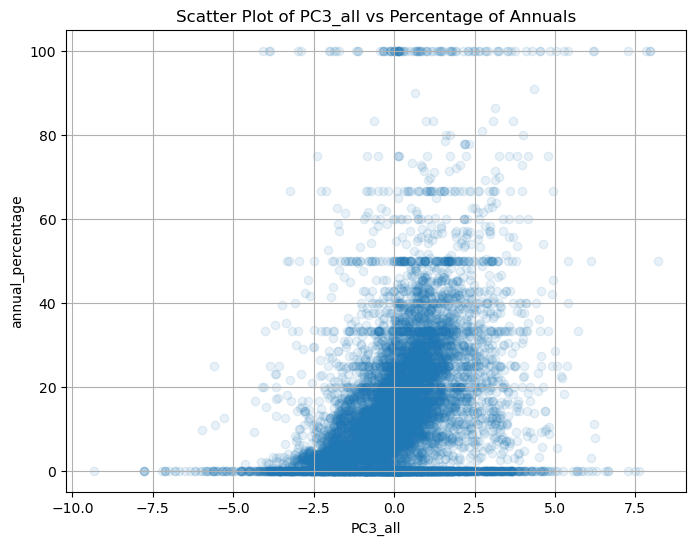

In [12]:
# plot PC3_all vs percentage_conifer
plt.figure(figsize=(8, 6))
plt.scatter(gdf['PC3_all'], gdf['annual_percentage'], alpha=0.1)
plt.xlabel('PC3_all')
plt.ylabel('annual_percentage')
plt.title('Scatter Plot of PC3_all vs Percentage of Annuals')
plt.grid(True)

# Add Regions

## IPCC

In [ ]:
ipcc_srex = gpd.read_file("./Data/IPCC_SREX/IPCC-WGI-reference-regions-v4.shp")

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

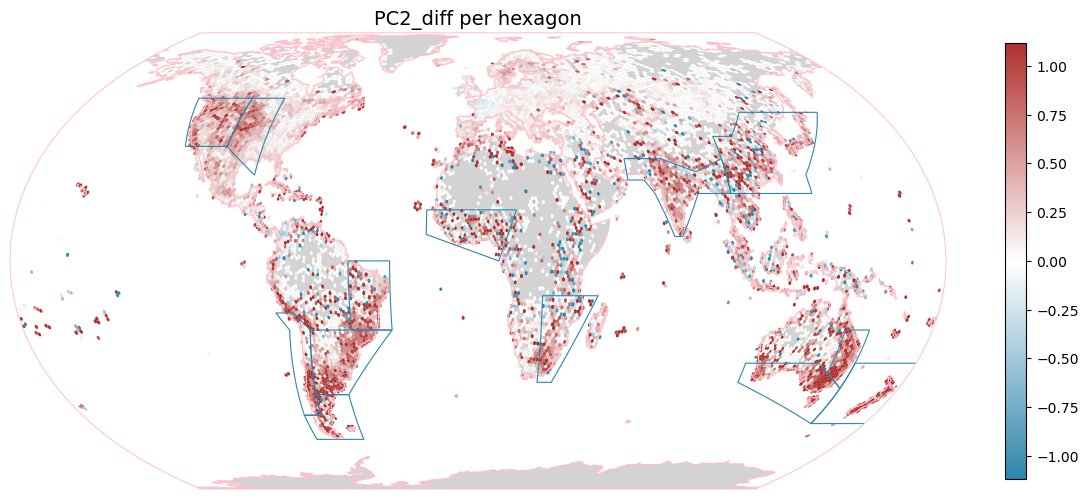

In [ ]:
import os
import numpy as np
from matplotlib import colormaps


#pattern = "perc_"
#pattern = "count_"
#pattern = "X"
pattern = "PC2_diff"

#pattern = "PC1_all"
#pattern = "PC2_percent_change"


# Ensure the results directory exists
os.makedirs("Results/Figures", exist_ok=True)

# Loop over all columns that start with "X"
for column in [col for col in gdf.columns if col.startswith(pattern)]: 
#for column in [col for col in gdf.columns if "percent_change" in col]:
#for column in [col for col in gdf.columns if col.endswith("percent_change_median")]:
#for column in [col for col in gdf.columns if col.endswith("p_value")]:
#for column in [col for col in gdf.columns if col.endswith("rank_biserial_r")]:

    if "percent_change" in column:
        vmin, vmax = -80, 80
        cmap = div_cmap
    elif "rank_biserial_r" in column:
        vmin, vmax = -0.7, 0.7
        cmap = div_cmap
    elif "perc_naturalized" in column:
        cmap = "YlGnBu"
        vmin, vmax = 0, 100
    elif "PC1_diff" in column:
        vmin = np.nanpercentile(gdf["PC1_diff"], 5)
        vmax = np.nanpercentile(gdf["PC1_diff"], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    elif "PC2_diff" in column:
        vmin = np.nanpercentile(gdf["PC1_diff"], 5)
        vmax = np.nanpercentile(gdf["PC1_diff"], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    elif "PC3_diff" in column:
        vmin = np.nanpercentile(gdf["PC1_diff"], 5)
        vmax = np.nanpercentile(gdf["PC1_diff"], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    elif "PC4_diff" in column:
        vmin = np.nanpercentile(gdf["PC1_diff"], 5)
        vmax = np.nanpercentile(gdf["PC1_diff"], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    else:
        vmin = np.nanpercentile(gdf[column], 1)
        vmax = np.nanpercentile(gdf[column], 99)
        cmap = "YlGnBu"
        
    # Create plot with Robinson projection
    fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.EqualEarth()})
    #fig, ax = plt.subplots(figsize=(32, 18), subplot_kw={'projection': ccrs.EqualEarth()})
    
    ax.set_global()
    #ax.add_feature(cfeature.LAND, facecolor='#2F86AC', edgecolor='none')
    ax.add_feature(cfeature.LAND, facecolor='lightgrey', edgecolor='none')
    #ax.add_feature(cfeature.LAND, facecolor='#A7AE9C', edgecolor='none')
    
    ax._autoscaleXon = True
    ax._autoscaleYon = True


    # Plot hexagons
    gdf.plot(
        column=column,
        cmap=cmap,
        vmin = vmin,
        vmax = vmax,
        legend=True,
        ax=ax,
        transform=ccrs.PlateCarree(),
        #edgecolor="black",
        linewidth=0.001,
        legend_kwds={"shrink": 0.45}
    )

    ax.set_title(f"{column} per hexagon", fontsize=14)
    #ax.set_title(f"Community science observations: {column} per hexagon", fontsize=14)
    #ax.set_title(f"GBIF sample (min. 1, max. 5000): Percent naturalized per hexagon", fontsize=14)
    
    #add coastlines
    #ax.coastlines(resolution='110m', color='#2F86AC', linewidth=0.7)
    ax.coastlines(resolution='110m', color='pink', linewidth=0.9)
    #ax.coastlines(resolution='110m', color='pink', linewidth=2)
    
    for spine in ax.spines.values():
        spine.set_edgecolor("pink")       # Color of the frame
        spine.set_linewidth(0.7)           # Thickness of the frame
        #spine.set_linewidth(2)

    # Filter and plot region polygons (excluding oceans)
    #sig_regions =["CNA", "EAS", "EAU", "EEU", "ENA" ,"MED", "NEU", "NZ",  "SAS", "SAU" ,
     #            "SEA", "SSA", "WCE" ,"WNA"] # PC1 significant regions
    
    sig_regions = ["CNA", "EAS", "EAU", "ESAF", "NES", "NZ", "SAS", "SAU", "SES", "SIO", 
                   "SSA", "SWS", "WAF", "WNA"]  # PC2 significant regions
    
    #sig_regions = ["CNA", "EAS", "ENA", "NES", "NZ",  "SEA", "WAF", "WNA"]  # PC3 significant regions


    regions = ipcc_srex[(ipcc_srex["Type"] != "Ocean") & (ipcc_srex["Acronym"].isin(sig_regions))]
    regions.plot(
        ax=ax,
        facecolor="none",
        edgecolor="#2F86AC",
        linewidth=0.8,
        transform=ccrs.PlateCarree()
    )
    # Add region acronyms
    # for idx, row in regions.iterrows():
    #     if row["Type"] != "Ocean":  # Ensure only non-ocean regions are labeled
    #         point = row.geometry.representative_point()
    #         ax.text(
    #             point.x, point.y, row["Acronym"],
    #             fontsize=7,
    #             ha="center", va="center",
    #             transform=ccrs.PlateCarree(),
    #             color="black",
    #             bbox=dict(facecolor="white", edgecolor="none", alpha=0.4, boxstyle="round,pad=0.2")
    #         )

    plt.tight_layout()
    
    # Save the plot
    output_path = f"Results/Figures/{column}_meanbased_trim01_GBIF_wcvp_CS_IPCC_no_labels.png"
    #plt.savefig(output_path, format="pdf")
    plt.savefig(output_path, dpi=500, bbox_inches='tight')
    
    # Show the plot
    plt.show()

    

## Olsen

In [18]:
import geopandas as gpd
from os.path import expanduser

# Expand the user path and read the aggregated shapefile
wwf_aggregated = gpd.read_file(expanduser("~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp"))


In [19]:
#wwf_aggregated.head()

In [20]:
#sig_regions =[ "12_PA", "1_IM",  "2_IM",  "4_NA"  ] #PC1

#sig_regions = ["10_AT", "12_AA", "12_NA", "13_IM", "13_NA", "1_IM" , "1_NT",  "2_IM",  "4_AA" ,"4_NT",  "5_NA" , "7_AA",  "7_AT",  "7_NT",  "8_NA" , "8_NT" ] #PC2

sig_regions = ["10_AT", "13_NT" ,"1_IM",  "1_NT" , "2_IM" , "2_NT" , "4_AA",  "4_NA",  "5_NA", "6_NA" , "7_AT",  "8_NA" ] #PC3

#filter wwf_aggregated for sig_regions
wwf_aggregated = wwf_aggregated[wwf_aggregated["bim_rlm"].isin(sig_regions)]

In [21]:
# add column with realm extra (after the "_" in "bim_rlm")
wwf_aggregated['realm'] = wwf_aggregated['bim_rlm'].str.split('_').str[1]

In [22]:
# Simplify polygons with a lower tolerance value
wwf_aggregated['geometry'] = wwf_aggregated['geometry'].simplify(tolerance=0.001, preserve_topology=True)

# add buffer around polygons
wwf_aggregated['geometry'] = wwf_aggregated['geometry'].buffer(1)

/tmp/ipykernel_318699/816051289.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  wwf_aggregated['geometry'] = wwf_aggregated['geometry'].buffer(1)


In [23]:
wwf_aggregated

,bim_rlm,geometry,realm
1,10_AT,"MULTIPOLYGON (((47.99919 -13.64875, 48.00086 -...",AT
18,13_NT,"MULTIPOLYGON (((-28.87077 0.00432, -28.87346 0...",NT
26,1_IM,"MULTIPOLYGON (((126.65918 25.96757, 126.65677 ...",IM
27,1_NT,"MULTIPOLYGON (((-31.12351 -21.11327, -31.14885...",NT
32,2_IM,"MULTIPOLYGON (((93.52668 23.35568, 93.52469 23...",IM
34,2_NT,"MULTIPOLYGON (((-43.39739 -17.61030, -43.41137...",NT
39,4_AA,"MULTIPOLYGON (((165.85886 -46.79101, 165.80758...",AA
41,4_NA,"MULTIPOLYGON (((-99.58735 28.43431, -99.60595 ...",NA
45,5_NA,"MULTIPOLYGON (((-96.90918 30.44398, -96.91138 ...",NA
47,6_NA,"POLYGON ((-165.93363 54.39629, -165.93976 54.4...",NA


In [24]:
import os
import numpy as np
from matplotlib import colormaps


#pattern = "perc_"
#pattern = "count_"
#pattern = "X"
pattern = "PC3_diff"
#pattern = "PC1_all"
#pattern = "PC2_percent_change"


# Ensure the results directory exists
os.makedirs("Results/Figures", exist_ok=True)

# Loop over all columns that start with "X"
for column in [col for col in gdf.columns if col.startswith(pattern)]: 
#for column in [col for col in gdf.columns if "percent_change" in col]:
#for column in [col for col in gdf.columns if col.endswith("percent_change_median")]:
#for column in [col for col in gdf.columns if col.endswith("p_value")]:
#for column in [col for col in gdf.columns if col.endswith("rank_biserial_r")]:

    if "percent_change" in column:
        vmin, vmax = -80, 80
        cmap = div_cmap
    elif "rank_biserial_r" in column:
        vmin, vmax = -0.7, 0.7
        cmap = div_cmap
    elif "perc_naturalized" in column:
        cmap = "YlGnBu"
        vmin, vmax = 0, 100
    elif "PC1_diff" in column:
        vmin = np.nanpercentile(gdf["PC1_diff"], 5)
        vmax = np.nanpercentile(gdf["PC1_diff"], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    elif "PC2_diff" in column:
        vmin = np.nanpercentile(gdf["PC1_diff"], 5)
        vmax = np.nanpercentile(gdf["PC1_diff"], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    elif "PC3_diff" in column:
        vmin = np.nanpercentile(gdf["PC1_diff"], 5)
        vmax = np.nanpercentile(gdf["PC1_diff"], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    elif "PC4_diff" in column:
        vmin = np.nanpercentile(gdf["PC1_diff"], 5)
        vmax = np.nanpercentile(gdf["PC1_diff"], 95)
        vmax = max(abs(vmin), abs(vmax))
        vmin = -vmax
        cmap = div_cmap
    else:
        vmin = np.nanpercentile(gdf[column], 1)
        vmax = np.nanpercentile(gdf[column], 99)
        cmap = "YlGnBu"
        
    # Create plot with Robinson projection
    fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.EqualEarth()})
    #fig, ax = plt.subplots(figsize=(32, 18), subplot_kw={'projection': ccrs.EqualEarth()})
    
    ax.set_global()
    #ax.add_feature(cfeature.LAND, facecolor='#2F86AC', edgecolor='none')
    ax.add_feature(cfeature.LAND, facecolor="#afafafff", edgecolor='none')
    ax.add_feature(cfeature.OCEAN, facecolor="#dad8eaff", edgecolor='none')
    #ax.add_feature(cfeature.LAND, facecolor='#A7AE9C', edgecolor='none')
    
    ax._autoscaleXon = True
    ax._autoscaleYon = True


    # Plot hexagons
    gdf.plot(
        column=column,
        cmap=cmap,
        vmin = vmin,
        vmax = vmax,
        legend=True,
        ax=ax,
        transform=ccrs.PlateCarree(),
        #edgecolor="black",
        linewidth=0.001,
        legend_kwds={"shrink": 0.45}
    )

    ax.set_title(f"{column} per hexagon", fontsize=14)
    #ax.set_title(f"Community science observations: {column} per hexagon", fontsize=14)
    #ax.set_title(f"GBIF sample (min. 1, max. 5000): Percent naturalized per hexagon", fontsize=14)
    
    #add coastlines
    #ax.coastlines(resolution='110m', color='#2F86AC', linewidth=0.7)
    #ax.coastlines(resolution='110m', color="#0A415963", linewidth=0.7)
    #ax.coastlines(resolution='110m', color='pink', linewidth=2)
    
    for spine in ax.spines.values():
        spine.set_edgecolor("#dad8eaff")
        # Color of the frame
        spine.set_linewidth(0.7)           # Thickness of the frame
        #spine.set_linewidth(2)

    regions = wwf_aggregated.dissolve(by='realm')
    regions.plot(
        ax=ax,
        facecolor="none",
        edgecolor="#045A7FFF",
        linewidth=1.1,
        transform=ccrs.PlateCarree()
    )
    # Add region acronyms
    #for idx, row in regions.iterrows():
     #   point = row.geometry.representative_point()
      #  ax.text(
       #     point.x, point.y, row["realm"],
        #    fontsize=7,
         #   ha="center", va="center",
          #  transform=ccrs.PlateCarree(),
           # color="black",
            #bbox=dict(facecolor="white", edgecolor="none", alpha=0.4, boxstyle="round,pad=0.2")
        #)

    plt.tight_layout()
    
    # Save the plot
    output_path = f"Results/Figures/{column}_meanbased_trim01_GBIF_wcvp_CS_Olsen_log10.png"
    #plt.savefig(output_path, format="pdf")
    plt.savefig(output_path, dpi=500, bbox_inches='tight')
    
    # Show the plot
    plt.show()

    

NameError: name 'div_cmap' is not defined

In [29]:
import geopandas as gpd
from os.path import expanduser

# Expand the user path and read the aggregated shapefile
wwf_aggregated = gpd.read_file(expanduser("~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp"))


/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

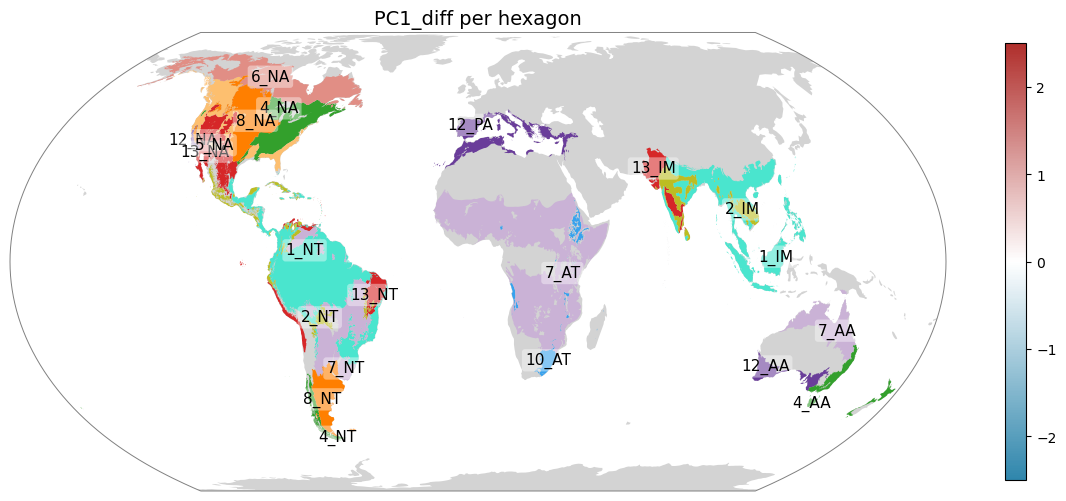

In [33]:
import os
import numpy as np
from matplotlib import colormaps


#pattern = "perc_"
#pattern = "count_"
#pattern = "X"
pattern = "PC1_diff"
#pattern = "PC1_all"
#pattern = "PC2_percent_change"


# Ensure the results directory exists
os.makedirs("Results/Figures", exist_ok=True)

# Loop over all columns that start with "X"
for column in [col for col in gdf.columns if col.startswith(pattern)]: 
#for column in [col for col in gdf.columns if "percent_change" in col]:
#for column in [col for col in gdf.columns if col.endswith("percent_change_median")]:
#for column in [col for col in gdf.columns if col.endswith("p_value")]:
#for column in [col for col in gdf.columns if col.endswith("rank_biserial_r")]:

    if "percent_change" in column:
        vmin, vmax = -80, 80
        cmap = div_cmap
    elif "rank_biserial_r" in column:
        vmin, vmax = -0.7, 0.7
        cmap = div_cmap
    elif "perc_naturalized" in column:
        cmap = "YlGnBu"
        vmin, vmax = 0, 100
    elif "PC1_diff" in column:
        vmin, vmax = -2.5, 2.5
        cmap = div_cmap
    elif "PC2_diff" in column:
        vmin, vmax = -2.5, 2.5
        cmap = div_cmap
    else:
        vmin = np.nanpercentile(gdf[column], 1)
        vmax = np.nanpercentile(gdf[column], 99)
        cmap = "YlGnBu"
        
    # Create plot with Robinson projection
    fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.EqualEarth()})
    #fig, ax = plt.subplots(figsize=(32, 18), subplot_kw={'projection': ccrs.EqualEarth()})
    
    ax.set_global()
    #ax.add_feature(cfeature.LAND, facecolor='#2F86AC', edgecolor='none')
    ax.add_feature(cfeature.LAND, facecolor='lightgrey', edgecolor='none')
    #ax.add_feature(cfeature.LAND, facecolor='#A7AE9C', edgecolor='none')
    
    ax._autoscaleXon = True
    ax._autoscaleYon = True


    # Plot hexagons
    gdf.plot(
        column=column,
        cmap=cmap,
        vmin = vmin,
        vmax = vmax,
        legend=True,
        ax=ax,
        transform=ccrs.PlateCarree(),
        #edgecolor="black",
        linewidth=0,
        alpha=0,
        legend_kwds={"shrink": 0.45}
    )

    ax.set_title(f"{column} per hexagon", fontsize=14)
    #ax.set_title(f"Community science observations: {column} per hexagon", fontsize=14)
    #ax.set_title(f"GBIF sample (min. 1, max. 5000): Percent naturalized per hexagon", fontsize=14)
    
    #add coastlines
    #ax.coastlines(resolution='110m', color='#2F86AC', linewidth=0.7)
    #ax.coastlines(resolution='110m', color='pink', linewidth=0.9)
    #ax.coastlines(resolution='110m', color='pink', linewidth=2)
    
    for spine in ax.spines.values():
        spine.set_edgecolor("grey")       # Color of the frame
        spine.set_linewidth(0.7)           # Thickness of the frame
        #spine.set_linewidth(2)

    # Filter and plot region polygons (excluding oceans)
    # PC1 significant regions
    #sig_regions =[ "12_PA", "1_IM",  "2_IM",  "4_NA",  "8_NA",  "8_NT",  "8_PA" ]
    
    # PC2 significant regions
    #sig_regions = ["13_IM", "1_IM",  "2_IM",  "4_AA",  "4_NT",  "5_NA",  "7_AA",  "8_NA",  "8_NT" ]

    sig_regions = [
        "12_PA", "1_IM", "2_IM", "4_NA", "10_AT", "12_AA", "12_NA", "13_IM",
        "13_NA", "1_NT", "4_AA", "4_NT", "5_NA", "7_AA", "7_AT", "7_NT",
        "8_NA", "8_NT", "13_NT", "2_NT", "6_NA"
    ]


    regions = wwf_aggregated[wwf_aggregated["bim_rlm"].isin(sig_regions)]
    
    # color for each region based on all_regions
    
    # Ensure no NaN values in the color mapping
    facecolor_mapping = regions["bim_rlm"].map({
        "10_AT": "#37a2ee",
        "12_NA": "#6a3d9a",
        "12_PA": "#6a3d9a",
        "12_AA": "#6a3d9a",
        "13_IM": "#d62728",
        "13_NA": "#d62728",
        "13_NT": "#d62728",
        "1_IM": "#4ae5ce",
        "1_NT": "#4ae5ce",
        "2_IM": "#bcbd22",
        "2_NT": "#bcbd22",
        "4_AA": "#33a02c",
        "4_NA": "#33a02c",
        "4_NT": "#33a02c",
        "5_NA": "#fdbf6f",
        "6_NA": "#e18e85",
        "7_AA": "#cab2d6",
        "7_NT": "#cab2d6",
        "7_AT": "#cab2d6",
        "8_NA": "#ff7f00",
        "8_NT": "#ff7f00",
        "8_PA": "#ff7f00",
    }).fillna("#d3d3d3")  # Default to light grey for unmapped regions


    regions.plot(
        ax=ax,
        facecolor=facecolor_mapping,
        linewidth=0.8,
        transform=ccrs.PlateCarree()
    )

    # Add region acronyms (optional)
    for idx, row in regions.iterrows():
        point = row.geometry.representative_point()
        ax.text(
            point.x, point.y, row["bim_rlm"],
            fontsize=11,
            ha="center", va="center",
            transform=ccrs.PlateCarree(),
            color="black",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.4, boxstyle="round,pad=0.2")
        )

    plt.tight_layout()
    
    # Save the plot
    output_path = f"Results/Figures/{column}_meanbased_trim01_GBIF_wcvp_CS_Olsen_plain_log10.png"
    #plt.savefig(output_path, format="pdf")
    plt.savefig(output_path, dpi=500, bbox_inches='tight')
    
    # Show the plot
    plt.show()

    